# Day 9: Exploratory Data Analysis (EDA)

This notebook explores the cleaned weather data from Day 8. It examines data quality, summary statistics, time patterns, distributions, relationships, and unusual temperature values.

## 1. Import Libraries and Load Data

The timestamp is parsed with `utc=True` so that its existing `+00:00` timezone information is preserved consistently.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid', palette='deep')

file_path = '../Day-8/cleaned_weather.csv'
weather = pd.read_csv(file_path)
weather['formatted_date'] = pd.to_datetime(
    weather['formatted_date'], utc=True, errors='coerce'
)

print(f'Dataset shape: {weather.shape}')
print(f'Date range: {weather["formatted_date"].min()} to {weather["formatted_date"].max()}')

Dataset shape: (96429, 12)
Date range: 2005-12-31 23:00:00+00:00 to 2016-12-31 22:00:00+00:00


## 2. Dataset Structure and Data Quality

Inspect the schema first, then check whether missing values or exact duplicate rows need attention.

In [2]:
print('Columns:')
print(weather.columns.tolist())

print('\nData types:')
print(weather.dtypes)

print('\nMissing values:')
print(weather.isna().sum())

print(f'\nExact duplicate records: {weather.duplicated().sum()}')

Columns:
['formatted_date', 'summary', 'precip_type', 'temperature_c', 'apparent_temperature_c', 'humidity', 'wind_speed_km_h', 'wind_bearing_degrees', 'visibility_km', 'loud_cover', 'pressure_millibars', 'daily_summary']

Data types:
formatted_date            datetime64[ns, UTC]
summary                                object
precip_type                            object
temperature_c                         float64
apparent_temperature_c                float64
humidity                              float64
wind_speed_km_h                       float64
wind_bearing_degrees                  float64
visibility_km                         float64
loud_cover                            float64
pressure_millibars                    float64
daily_summary                          object
dtype: object

Missing values:
formatted_date            0
summary                   0
precip_type               0
temperature_c             0
apparent_temperature_c    0
humidity                  0
wind_speed_km_

In [3]:
print('Descriptive statistics for numerical features:')
display(weather.describe().T.round(2))

Descriptive statistics for numerical features:


,count,mean,std,min,25%,50%,75%,max
temperature_c,96429.0,11.93,9.55,-21.82,4.68,12.00,18.84,39.91
apparent_temperature_c,96429.0,10.85,10.70,-27.72,2.31,12.00,18.84,39.34
humidity,96429.0,0.73,0.20,0.00,0.60,0.78,0.89,1.00
wind_speed_km_h,96429.0,10.81,6.91,0.00,5.83,9.97,14.14,63.85
wind_bearing_degrees,96429.0,187.50,107.38,0.00,116.00,180.00,290.00,359.00
visibility_km,96429.0,10.35,4.19,0.00,8.34,10.05,14.81,16.10
loud_cover,96429.0,0.00,0.00,0.00,0.00,0.00,0.00,0.00
pressure_millibars,96429.0,1003.23,116.98,0.00,1011.90,1016.45,1021.09,1046.38


**Observation:** The cleaned dataset contains 96,429 records and has no missing values or exact duplicate rows. Temperature ranges from -21.82 C to 39.91 C, so the data captures both cold and hot conditions.

## 3. Feature Engineering for Time Analysis

Calendar month and season make the temporal comparisons easier to read. Meteorological seasons are used: winter (Dec-Feb), spring (Mar-May), summer (Jun-Aug), and autumn (Sep-Nov).

In [4]:
weather['month'] = weather['formatted_date'].dt.month
weather['season'] = np.select(
    [
        weather['month'].isin([12, 1, 2]),
        weather['month'].isin([3, 4, 5]),
        weather['month'].isin([6, 7, 8]),
        weather['month'].isin([9, 10, 11]),
    ],
    ['Winter', 'Spring', 'Summer', 'Autumn'],
    default='Unknown'
)

month_names = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun',
               'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
monthly_temperature = weather.groupby('month')['temperature_c'].mean()
season_order = ['Winter', 'Spring', 'Summer', 'Autumn']
seasonal_temperature = weather.groupby('season')['temperature_c'].agg(['mean', 'median', 'count']).reindex(season_order)

display(seasonal_temperature.round(2))

,mean,median,count
season,,,
Winter,1.52,1.56,23832
Spring,12.18,12.20,24288
Summer,22.02,21.46,24285
Autumn,11.80,11.18,24024


## 4. Monthly Average Temperature Trend

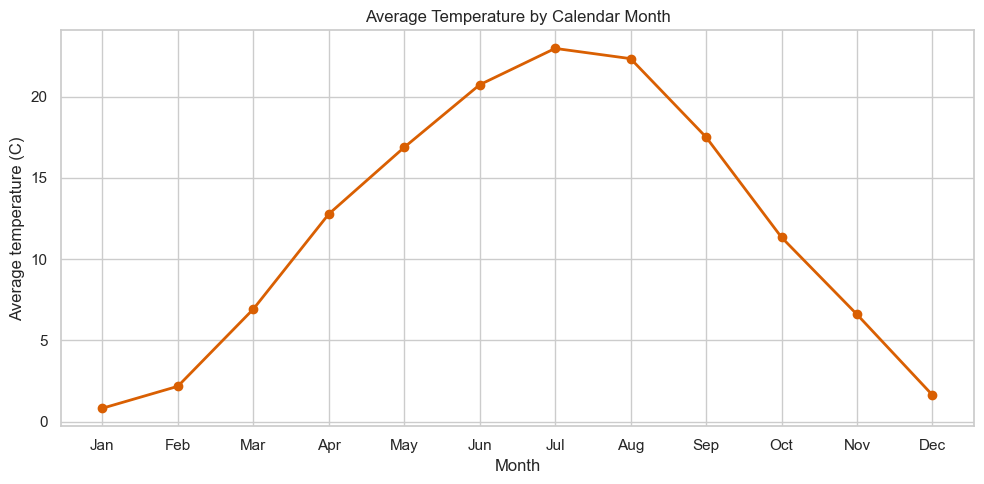

Warmest month: Jul (22.97 C)
Coolest month: Jan (0.82 C)


In [5]:
plt.figure(figsize=(10, 5))
plt.plot(month_names, monthly_temperature.values, marker='o', linewidth=2, color='#d95f02')
plt.title('Average Temperature by Calendar Month')
plt.xlabel('Month')
plt.ylabel('Average temperature (C)')
plt.tight_layout()
plt.show()

warmest_month = monthly_temperature.idxmax()
coolest_month = monthly_temperature.idxmin()
print(f'Warmest month: {month_names[warmest_month - 1]} ({monthly_temperature.max():.2f} C)')
print(f'Coolest month: {month_names[coolest_month - 1]} ({monthly_temperature.min():.2f} C)')

**Observation:** Average temperature climbs from 0.82 C in January to a July high of 22.97 C, then declines towards winter. The 22.15 C gap shows a clear annual seasonal cycle.

## 5. Temperature Distribution

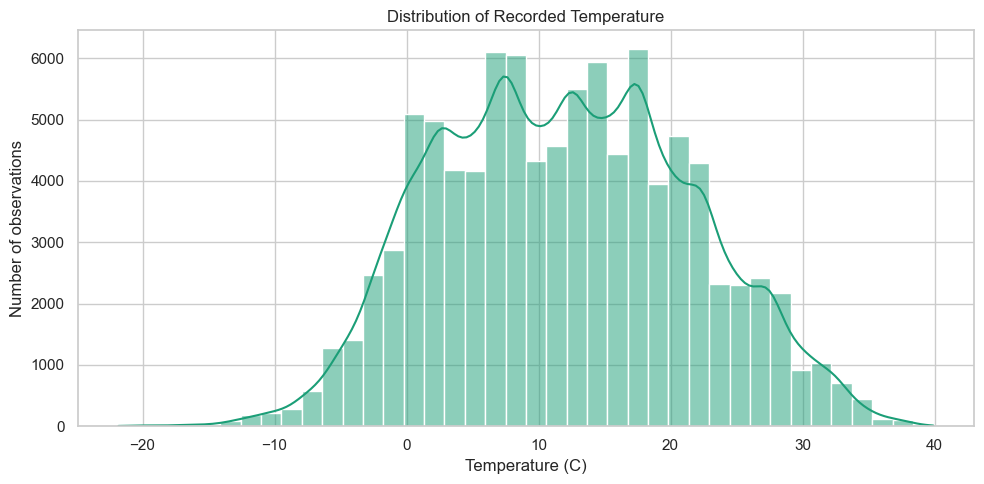

5th percentile     -2.77
Median             12.00
95th percentile    27.78
Name: temperature_c, dtype: float64


In [6]:
plt.figure(figsize=(10, 5))
sns.histplot(data=weather, x='temperature_c', bins=40, kde=True, color='#1b9e77')
plt.title('Distribution of Recorded Temperature')
plt.xlabel('Temperature (C)')
plt.ylabel('Number of observations')
plt.tight_layout()
plt.show()

print(weather['temperature_c'].quantile([0.05, 0.50, 0.95]).rename({0.05: '5th percentile', 0.50: 'Median', 0.95: '95th percentile'}).round(2))

**Observation:** The median temperature is 12.00 C. The middle 90% of readings span -2.77 C to 27.78 C, while the full range is wider because of infrequent extreme cold and heat.

## 6. Temperature and Humidity Relationship

A reproducible sample keeps the plot readable while retaining a representative selection of observations.

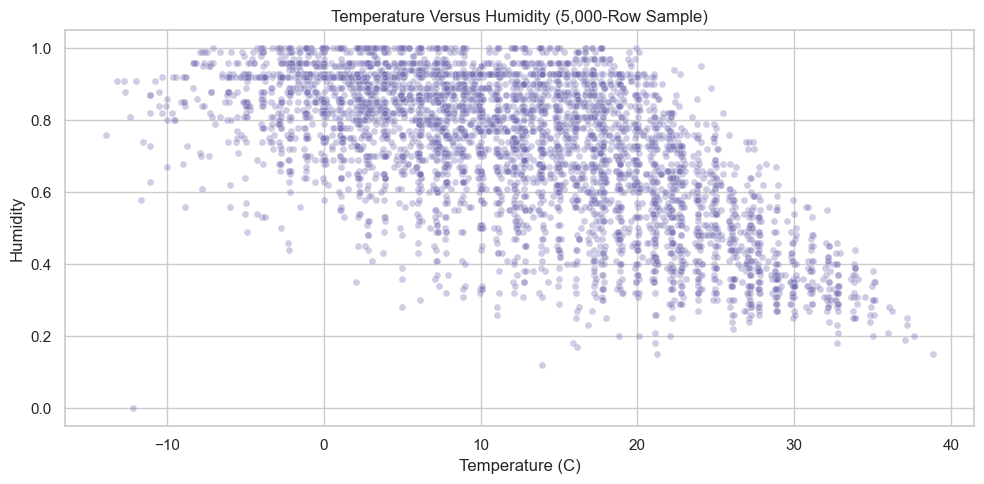

Pearson correlation: -0.632


In [7]:
scatter_sample = weather.sample(n=5000, random_state=42)
temperature_humidity_correlation = weather['temperature_c'].corr(weather['humidity'])

plt.figure(figsize=(10, 5))
sns.scatterplot(data=scatter_sample, x='temperature_c', y='humidity', alpha=0.35, s=25, color='#7570b3')
plt.title('Temperature Versus Humidity (5,000-Row Sample)')
plt.xlabel('Temperature (C)')
plt.ylabel('Humidity')
plt.tight_layout()
plt.show()

print(f'Pearson correlation: {temperature_humidity_correlation:.3f}')

**Observation:** Temperature and humidity have a moderate negative Pearson correlation of -0.632 in this dataset. This is an association, not evidence that temperature causes humidity to change.

## 7. Seasonal Temperature Comparison

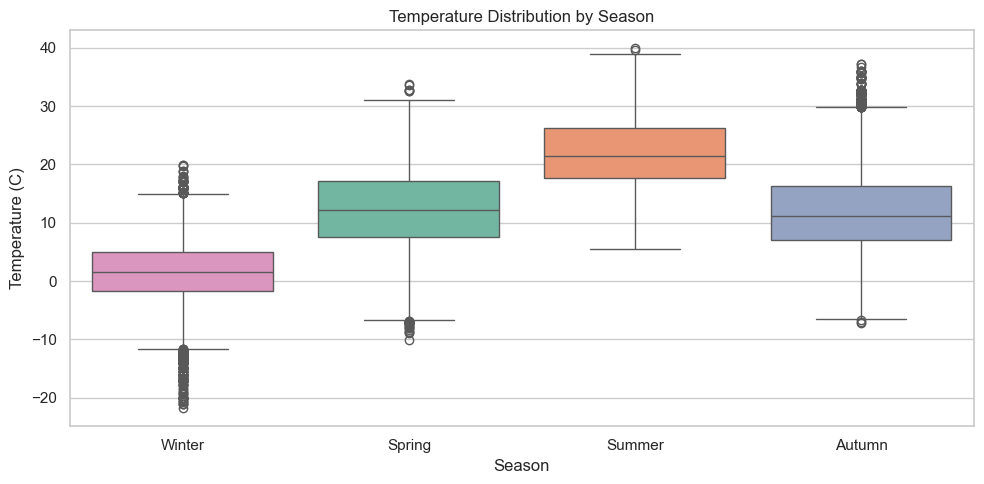

,mean,median,count
season,,,
Winter,1.52,1.56,23832
Spring,12.18,12.20,24288
Summer,22.02,21.46,24285
Autumn,11.80,11.18,24024


In [8]:
plt.figure(figsize=(10, 5))
sns.boxplot(data=weather, x='season', y='temperature_c', hue='season', order=season_order, legend=False, palette='Set2')
plt.title('Temperature Distribution by Season')
plt.xlabel('Season')
plt.ylabel('Temperature (C)')
plt.tight_layout()
plt.show()

display(seasonal_temperature.round(2))

**Observation:** Summer has the highest mean temperature (22.02 C), and winter the lowest (1.52 C). Their mean difference is 20.51 C, though the box plots also show that unusual days can overlap seasons.

## 8. Numerical Feature Correlations

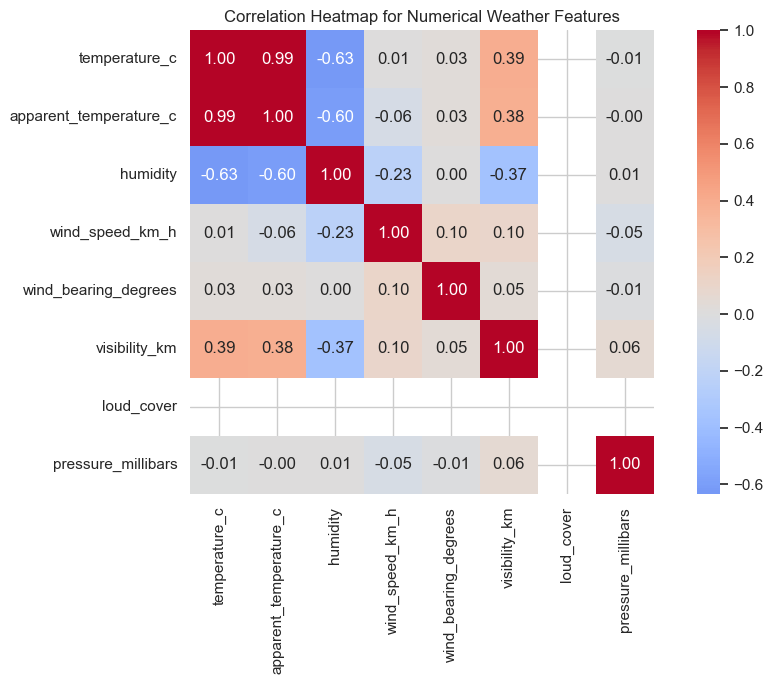

humidity                 -0.632
pressure_millibars       -0.005
wind_speed_km_h           0.009
wind_bearing_degrees      0.030
visibility_km             0.393
apparent_temperature_c    0.993
temperature_c             1.000
loud_cover                  NaN
Name: temperature_c, dtype: float64


In [9]:
numeric_columns = weather.select_dtypes(include='number').columns.drop(['month'])
correlation_matrix = weather[numeric_columns].corr()

plt.figure(figsize=(10, 7))
sns.heatmap(correlation_matrix, annot=True, fmt='.2f', cmap='coolwarm', center=0, square=True)
plt.title('Correlation Heatmap for Numerical Weather Features')
plt.tight_layout()
plt.show()

print(correlation_matrix['temperature_c'].sort_values().round(3))

**Observation:** Temperature and apparent temperature are very strongly associated (0.993), while visibility has a moderate positive association with temperature (0.393). The `loud_cover` column is constant at zero, so its correlation is undefined and it adds no variation to this analysis.

## 9. Potential Temperature Outliers

The interquartile range (IQR) rule flags values below Q1 - 1.5 x IQR or above Q3 + 1.5 x IQR. These are unusual values, not automatically data errors.

In [10]:
q1, q3 = weather['temperature_c'].quantile([0.25, 0.75])
iqr = q3 - q1
lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr
outliers = weather[(weather['temperature_c'] < lower_bound) | (weather['temperature_c'] > upper_bound)]

print(f'Q1: {q1:.2f} C | Q3: {q3:.2f} C | IQR: {iqr:.2f} C')
print(f'IQR bounds: {lower_bound:.2f} C to {upper_bound:.2f} C')
print(f'Potential outliers: {len(outliers)} ({len(outliers) / len(weather):.3%} of records)')
print(f'Outlier temperature range: {outliers["temperature_c"].min():.2f} C to {outliers["temperature_c"].max():.2f} C')

Q1: 4.68 C | Q3: 18.84 C | IQR: 14.16 C
IQR bounds: -16.55 C to 40.07 C
Potential outliers: 44 (0.046% of records)
Outlier temperature range: -21.82 C to -16.67 C


**Observation:** The IQR rule flags 44 readings (0.046%), all on the cold side from -21.82 C to -16.67 C. Their rarity makes them useful cases for checking cold-weather readiness rather than grounds for automatic deletion.

## 10. Actionable Business Insights

1. **Plan seasonal capacity:** July averages 22.97 C versus 0.82 C in January, a 22.15 C difference. Businesses affected by outdoor demand can schedule more warm-season staff, inventory, or events while preparing winter alternatives.
2. **Budget for winter heating and resilience:** Winter averages 1.52 C, compared with 22.02 C in summer. Facilities teams can use this 20.51 C seasonal gap to plan heating demand, maintenance windows, and weather-sensitive operations.
3. **Use humidity as a planning signal, not a causal rule:** Temperature and humidity are moderately negatively associated (r = -0.632). Forecasting dashboards can monitor both variables together when planning comfort measures, but should not assume one variable causes the other.
4. **Avoid redundant temperature inputs in simple reports or models:** Apparent temperature has a 0.993 correlation with measured temperature. When a use case needs a compact set of inputs, validate whether both fields add value before retaining both.
5. **Maintain an extreme-cold response:** Only 44 records (0.046%) are IQR-flagged cold readings, reaching -21.82 C. Their low frequency supports targeted contingency stock, safety guidance, and alert procedures rather than treating them as normal conditions.

## 11. Conclusion

The dataset is complete and has a pronounced seasonal temperature cycle. The visualizations help communicate its distribution, the temperature-humidity association, seasonal variation, and numerical feature relationships. Correlation values describe patterns in these observations and do not establish causation.